In [1]:
%pip install pandas numpy scikit-learn ucimlrepo joblib streamlit

   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   ------ --------------------------------- 1.6/10.4 MB 7.2 MB/s eta 0:00:02
   ---------- ----------------------------- 2.6/10.4 MB 5.5 MB/s eta 0:00:02
   ---------- ----------------------------- 2.6/10.4 MB 5.5 MB/s eta 0:00:02
   ----------------- ---------------------- 4.5/10.4 MB 5.0 MB/s eta 0:00:02
   -------------------- ------------------- 5.2/10.4 MB 4.8 MB/s eta 0:00:02
   ----------------------- ---------------- 6.0/10.4 MB 4.5 MB/s eta 0:00:01
   ------------------------- -------------- 6.6/10.4 MB 4.4 MB/s eta 0:00:01
   --------------------------- ------------ 7.1/10.4 MB 4.0 MB/s eta 0:00:01
   ---------------------------- ----------- 7.3/10.4 MB 3.8 MB/s eta 0:00:01
   ------------------------------ --------- 7.9/10.4 MB 3.6 MB/s eta 0:00:01
   -------------------------------- ------- 8.4/10.4 MB 3.4 MB/s eta 0:00:01
   ----------


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\franc\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np

from ucimlrepo import fetch_ucirepo

# Download the UCI PhiUSIIL dataset
dataset = fetch_ucirepo(id=967)

X = dataset.data.features
y = dataset.data.targets

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Feature columns:", X.columns.tolist())
print("Target column:", y.columns.tolist())

Features shape: (235795, 54)
Target shape: (235795, 1)
Feature columns: ['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']
Target column: ['label']


In [3]:
# Find the URL column
url_column = next(
    col for col in X.columns
    if col.lower() == "url"
)

# Find the target column
target_column = y.columns[0]

# Create a clean dataframe
df = pd.DataFrame({
    "url": X[url_column],
    "label_raw": pd.to_numeric(
        y[target_column], errors="coerce"
    )
})

df = df.dropna()
df["url"] = df["url"].astype(str).str.strip()
df = df[df["url"] != ""]

# UCI PhiUSIIL labels:
# 0 = phishing, 1 = legitimate
df = df[df["label_raw"].isin([0, 1])].copy()

df["label"] = df["label_raw"].map({
    0: "Phishing",
    1: "Legitimate"
})

df = df[["url", "label"]].reset_index(drop=True)

print(df.head())
print("\nDataset size:", len(df))
print("\nClass distribution:")
print(df["label"].value_counts())

                                  url       label
0    https://www.southbankmosaics.com  Legitimate
1            https://www.uni-mainz.de  Legitimate
2      https://www.voicefmradio.co.uk  Legitimate
3         https://www.sfnmjournal.com  Legitimate
4  https://www.rewildingargentina.org  Legitimate

Dataset size: 235795

Class distribution:
label
Legitimate    134850
Phishing      100945
Name: count, dtype: int64


In [4]:
# Select up to 25,000 examples from each class
samples_per_class = min(
    25000,
    int(df["label"].value_counts().min())
)

df_small = pd.concat(
    [
        group.sample(
            n=samples_per_class,
            random_state=42
        )
        for _, group in df.groupby("label")
    ],
    ignore_index=True
)

df_small = df_small.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Training dataset size:", len(df_small))
print(df_small["label"].value_counts())

Training dataset size: 50000
label
Phishing      25000
Legitimate    25000
Name: count, dtype: int64


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df_small["url"],
    df_small["label"],
    test_size=0.20,
    random_state=42,
    stratify=df_small["label"]
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 40000
Testing examples: 10000


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            max_features=50000,
            min_df=2,
            dtype=np.float32
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


Accuracy: 99.38 %

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.99      1.00      0.99      5000
    Phishing       1.00      0.99      0.99      5000

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



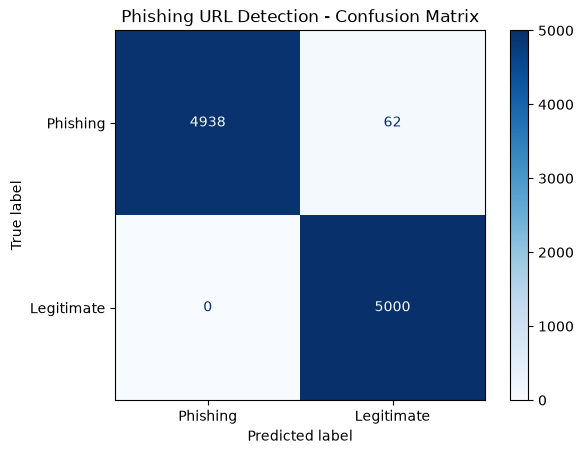

In [7]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred) * 100, 2
), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["Phishing", "Legitimate"],
    cmap="Blues"
)

plt.title("Phishing URL Detection - Confusion Matrix")
plt.show()

In [8]:
import joblib

joblib.dump(model, "phishing_url_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [9]:
results = pd.DataFrame({
    "url": X_test.values,
    "actual": y_test.values,
    "predicted": y_pred
})

correct = results[
    results["actual"] == results["predicted"]
]

demo_samples = pd.concat([
    correct[correct["actual"] == "Phishing"].head(3),
    correct[correct["actual"] == "Legitimate"].head(3)
])

demo_samples.to_csv("demo_samples.csv", index=False)

print("Verified demo examples saved:")
print(demo_samples[["actual", "url"]].to_string(index=False))

Verified demo examples saved:
    actual                                               url
  Phishing   http://www.amazceom-co-jp.amaczeon.chafalv.top/
  Phishing http://www.dev-banronlinesuper001.pantheonsite.io
  Phishing                      https://ijojgullv.top/jp.php
Legitimate                          https://www.ecrannoir.fr
Legitimate                             https://www.adaic.com
Legitimate                       https://www.house-autry.com


In [10]:

%%writefile app.py
import re
from pathlib import Path

import joblib
import pandas as pd
import streamlit as st

BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "phishing_url_model.joblib"
SAMPLES_PATH = BASE_DIR / "demo_samples.csv"

st.set_page_config(
    page_title="Phishing URL Detector",
    page_icon="🔐",
    layout="centered"
)

@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)

model = load_model()

def normalize_url(url):
    url = url.strip()

    if not re.match(r"^[a-zA-Z][a-zA-Z0-9+.-]*://", url):
        url = "http://" + url

    return url

st.title("🔐 Phishing Website Detector")

st.write(
    "Analyze a website URL using a machine learning model "
    "trained on the UCI PhiUSIIL phishing URL dataset."
)

st.info(
    "This is an educational ML prototype. Its predictions "
    "are estimates, not proof that a website is safe."
)

# Load correctly classified held-out examples for the expo
if SAMPLES_PATH.exists():
    samples = pd.read_csv(SAMPLES_PATH).dropna(
        subset=["url", "actual"]
    )

    options = ["Enter a URL yourself"]

    for i, row in samples.reset_index(drop=True).iterrows():
        options.append(
            f"Demo {i + 1}: {row['actual']}"
        )

    choice = st.selectbox(
        "Try a demonstration example (optional)",
        options
    )

    default_url = ""

    if choice != "Enter a URL yourself":
        index = options.index(choice) - 1
        default_url = str(
            samples.reset_index(drop=True).iloc[index]["url"]
        )
else:
    default_url = ""

url_input = st.text_input(
    "Enter the website URL",
    value=default_url,
    placeholder="https://example.com"
)

if st.button("Check Website", type="primary", use_container_width=True):
    if not url_input.strip():
        st.warning("Please enter a URL.")
    else:
        url = normalize_url(url_input)

        try:
            prediction = model.predict([url])[0]
            probabilities = model.predict_proba([url])[0]
            classes = list(model.classes_)

            score = float(
                probabilities[classes.index(prediction)]
            )

            st.divider()

            if prediction == "Phishing":
                st.error("⚠️ Potentially Phishing")
            else:
                st.success("✅ Likely Legitimate")

            st.metric(
                "Model score for predicted class",
                f"{score * 100:.1f}%"
            )

            st.caption(
                "This score is not a guarantee of safety. "
                "A new or unfamiliar URL may be misclassified."
            )

            with st.expander("What did the model analyze?"):
                st.write("Submitted URL:", url)
                st.write(
                    "The model analyzes character patterns "
                    "learned from labeled URLs. It does not "
                    "visit the website or inspect its live content."
                )

        except Exception as error:
            st.error("Prediction failed. Please check the input.")
            st.exception(error)


Writing app.py


In [ ]:
# Leakage-aware comparison: model selection uses validation data only.
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

uci_csv_url = "https://archive.ics.uci.edu/static/public/967/data.csv"
raw_eval = pd.read_csv(uci_csv_url, usecols=["URL", "label"])
raw_eval["URL"] = raw_eval["URL"].astype(str).str.strip()
raw_eval["label"] = pd.to_numeric(raw_eval["label"], errors="coerce")
raw_eval = raw_eval.dropna(subset=["URL", "label"])
raw_eval = raw_eval[raw_eval["label"].isin([0, 1])].copy()

# The source has repeated URLs but no conflicting URL labels. Deduplicate before splitting.
source_duplicate_urls = int(raw_eval["URL"].duplicated().sum())
conflicting_url_labels = int(
    raw_eval.groupby("URL")["label"].nunique().gt(1).sum()
)
raw_eval = raw_eval.drop_duplicates(subset=["URL"], keep="first")
raw_eval["target"] = raw_eval["label"].map({0: "Phishing", 1: "Legitimate"})
comparison_data = raw_eval[["URL", "target"]].rename(
    columns={"URL": "url", "target": "label"}
)

# Preserve the notebook's 25,000-per-class sample, with a held-out test set.
comparison_per_class = min(
    25000,
    int(comparison_data["label"].value_counts().min()),
)
comparison_sample = pd.concat(
    [
        group.sample(n=comparison_per_class, random_state=42)
        for _, group in comparison_data.groupby("label")
    ],
    ignore_index=True,
).sample(frac=1, random_state=42).reset_index(drop=True)

X_train_valid, X_test_clean, y_train_valid, y_test_clean = train_test_split(
    comparison_sample["url"],
    comparison_sample["label"],
    test_size=0.20,
    random_state=42,
    stratify=comparison_sample["label"],
)
X_train_clean, X_valid_clean, y_train_clean, y_valid_clean = train_test_split(
    X_train_valid,
    y_train_valid,
    test_size=0.25,
    random_state=43,
    stratify=y_train_valid,
)


def make_comparison_pipeline(analyzer, classifier):
    return Pipeline(
        [
            (
                "tfidf",
                TfidfVectorizer(
                    analyzer=analyzer,
                    ngram_range=(3, 5),
                    max_features=50000,
                    min_df=2,
                    dtype=np.float32,
                ),
            ),
            ("classifier", classifier),
        ]
    )


comparison_models = {
    "LogisticRegression char (3-5)": make_comparison_pipeline(
        "char",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42,
        ),
    ),
    "LinearSVC char (3-5)": make_comparison_pipeline(
        "char",
        LinearSVC(class_weight="balanced", random_state=42),
    ),
    "LogisticRegression char_wb (3-5)": make_comparison_pipeline(
        "char_wb",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42,
        ),
    ),
}

comparison_validation_rows = []
for model_name, candidate in comparison_models.items():
    candidate.fit(X_train_clean, y_train_clean)
    validation_predictions = candidate.predict(X_valid_clean)
    phishing_precision, phishing_recall, phishing_f1, _ = (
        precision_recall_fscore_support(
            y_valid_clean,
            validation_predictions,
            labels=["Phishing"],
            average="binary",
            zero_division=0,
        )
    )
    comparison_validation_rows.append(
        {
            "Model": model_name,
            "Validation accuracy": accuracy_score(
                y_valid_clean, validation_predictions
            ),
            "Phishing precision": phishing_precision,
            "Phishing recall": phishing_recall,
            "Phishing F1": phishing_f1,
        }
    )

validation_comparison = pd.DataFrame(comparison_validation_rows).sort_values(
    ["Phishing F1", "Phishing recall", "Phishing precision"],
    ascending=False,
).reset_index(drop=True)
display(validation_comparison)
selected_model_name = validation_comparison.loc[0, "Model"]
print("Selected using validation data only:", selected_model_name)

# This test split was not used for fitting, threshold changes, or model selection.
test_comparison_rows = []
selected_test_errors = None
for model_name, candidate in comparison_models.items():
    test_predictions = candidate.predict(X_test_clean)
    phishing_precision, phishing_recall, phishing_f1, _ = (
        precision_recall_fscore_support(
            y_test_clean,
            test_predictions,
            labels=["Phishing"],
            average="binary",
            zero_division=0,
        )
    )
    test_comparison_rows.append(
        {
            "Model": model_name,
            "Test accuracy": accuracy_score(y_test_clean, test_predictions),
            "Phishing precision": phishing_precision,
            "Phishing recall": phishing_recall,
            "Phishing F1": phishing_f1,
            "Confusion matrix [P->P, P->L; L->P, L->L]": confusion_matrix(
                y_test_clean,
                test_predictions,
                labels=["Phishing", "Legitimate"],
            ).tolist(),
        }
    )
    if model_name == selected_model_name:
        selected_test_errors = pd.DataFrame(
            {
                "url": X_test_clean.to_numpy(),
                "actual": y_test_clean.to_numpy(),
                "predicted": test_predictions,
            }
        )

test_comparison = pd.DataFrame(test_comparison_rows)
display(test_comparison)
selected_false_negatives = selected_test_errors[
    (selected_test_errors["actual"] == "Phishing")
    & (selected_test_errors["predicted"] == "Legitimate")
]
print("Source repeated URL rows removed:", source_duplicate_urls)
print("URLs with conflicting labels:", conflicting_url_labels)
print("Exact URL overlap between train and test:", len(set(X_train_clean) & set(X_test_clean)))
print("Selected model false negatives on untouched test:", len(selected_false_negatives))
display(selected_false_negatives.head(25))